# 05 · The particle filter

The grid of notebook 01 stored the belief everywhere; the Kalman filters assumed it was
Gaussian. A **particle filter** stores it as a cloud of $N$ weighted samples,
$$
\operatorname{bel}(x_t) \approx \sum_{i=1}^N w_t^{(i)}\,\delta\big(x - x_t^{(i)}\big),\qquad \sum_i w_t^{(i)} = 1 .
$$
The particles go where the probability is. The cloud can take any shape (arcs, several
separate bumps) and the models are used as they are, with no linearisation. Applied to robot
localisation this is **Monte Carlo localisation** (Dellaert, Fox, Burgard & Thrun, 1999).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path().resolve().parent))

import numpy as np
import matplotlib.pyplot as plt
from bayesian_filters import (World, simulate, ParticleFilter, EKF, run_filter, position_error,
                            position_rmse, systematic_resample, multinomial_resample,
                            effective_sample_size, motion_model)
from bayesian_filters import viz
viz.style()

## 1. From the Bayes filter to sampling

**Importance sampling.** To represent a density $p$ that we cannot sample, draw from a
*proposal* $q$ and weight each sample by $p/q$. Then
$\sum_i w^{(i)} g(x^{(i)}) \to \mathbb E_p[g]$ as $N \to \infty$.

**Sequential importance sampling (SIS).** Use the motion model as the proposal: move each
particle with a *sampled* noisy control,
$$
x_{t+1}^{(i)} \sim p(x_{t+1}\mid x_t^{(i)}, u_{t+1}) \qquad\text{(predict)},
$$
so the cloud represents $\overline{\operatorname{bel}}(x_{t+1})$. Then Bayes' rule says that
the posterior is the prior times the likelihood, so
$$
w_{t+1}^{(i)} \propto w_t^{(i)}\; p\big(z_{t+1}\mid x_{t+1}^{(i)}\big) \qquad\text{(update)}.
$$
That is the whole algorithm: *simulate* the motion, *score* against the measurement. The
sensor model is the same as for the Kalman filters, a product of Gaussians in range and
(wrapped) bearing over the visible landmarks.

**Log-weights.** With four landmarks the likelihoods of far-away particles are
$e^{-1000}$ and smaller, below what a float can hold. The implementation adds
log-likelihoods and normalises with `logsumexp`.

## 2. Weight degeneracy

Run SIS alone, starting from a Gaussian around the truth, and watch the **effective sample
size**
$$
\mathrm{ESS} = \frac{1}{\sum_i \big(w^{(i)}\big)^2} \in [1, N],
$$
which is $N$ for equal weights and $1$ when one particle carries all the weight.

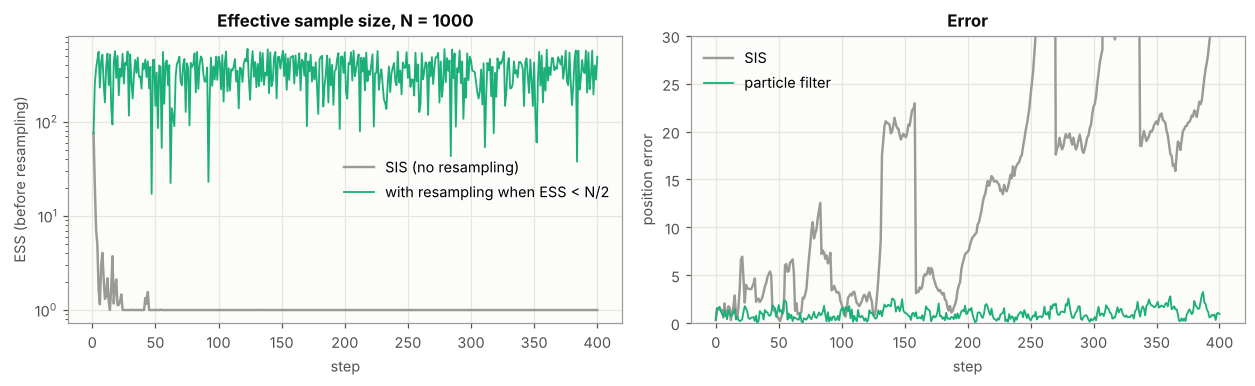

SIS: ESS < 2 from step 5;  PF resampled at 85% of the steps


In [2]:
world = World.default()
run = simulate(world, n_steps=400, seed=1)
P0 = np.diag([10.0, 10.0, 0.05])

sis = ParticleFilter(world, 1000, init=(run.truth[0], P0), resample_threshold=0.0, seed=0)  # never resample
pf = ParticleFilter(world, 1000, init=(run.truth[0], P0), resample_threshold=0.5, seed=0)
r_sis, r_pf = run_filter(sis, run), run_filter(pf, run)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 3.6))
a1.plot(np.arange(1, 401), sis.ess_history, color=viz.MUTED, lw=1.6, label="SIS (no resampling)")
a1.plot(np.arange(1, 401), pf.ess_history, color=viz.COLORS["PF"], lw=1.2, label="with resampling when ESS < N/2")
a1.set_yscale("log"); a1.set_xlabel("step"); a1.set_ylabel("ESS (before resampling)"); a1.legend()
a1.set_title("Effective sample size, N = 1000")
a2.plot(position_error(r_sis.means, run.truth), color=viz.MUTED, lw=1.6, label="SIS")
a2.plot(position_error(r_pf.means, run.truth), color=viz.COLORS["PF"], lw=1.2, label="particle filter")
a2.set_ylim(0, 30); a2.set_xlabel("step"); a2.set_ylabel("position error"); a2.legend(); a2.set_title("Error")
plt.tight_layout(); plt.show()
print(f"SIS: ESS < 2 from step {np.argmax(np.array(sis.ess_history) < 2) + 1};  "
      f"PF resampled at {np.mean(pf.resampled_history):.0%} of the steps")

Within a few steps one particle has all the weight: the other 999 are wasted computation,
and the estimate drifts away with that single survivor. The variance of the weights can only
grow over time (Kong, Liu & Wong, 1994). **Resampling** fixes this. Draw $N$ new particles
from the current ones with probabilities $w^{(i)}$ and reset all weights to $1/N$. Likely
particles are duplicated, unlikely ones die. The cloud then represents the same distribution,
with the effort moved to where the probability is.

## 3. How to resample

* **Multinomial**: $N$ independent draws from the weights. Simple, but noisy: the number of
  copies of particle $i$ is $\operatorname{Binomial}(N, w^{(i)})$.
* **Systematic**: one uniform $U \sim \mathcal U[0, 1/N)$ and the $N$ evenly spaced pointers
  $U + k/N$ into the cumulative weights. Every particle gets
  $\lfloor N w^{(i)}\rfloor$ or $\lceil N w^{(i)}\rceil$ copies, so the resampling adds almost
  no noise. It is the default here.

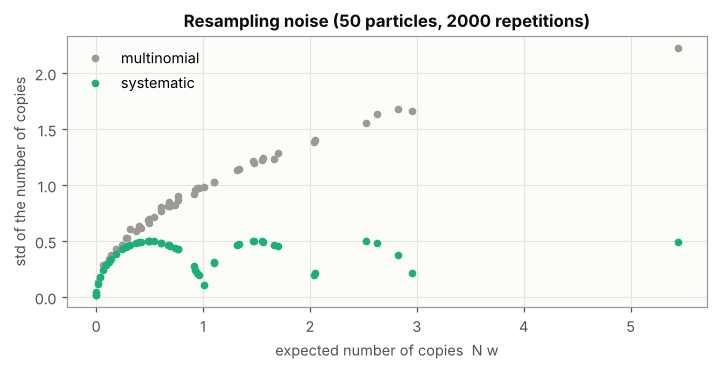

In [3]:
rng = np.random.default_rng(0)
w = rng.dirichlet(np.ones(50))
N = len(w)
cm, cs = [], []
for _ in range(2000):
    cm.append(np.bincount(multinomial_resample(w, rng), minlength=N))
    cs.append(np.bincount(systematic_resample(w, rng), minlength=N))
cm, cs = np.array(cm), np.array(cs)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
order = np.argsort(w)
ax.plot(N * w[order], cm.std(0)[order], "o", ms=4, color=viz.MUTED, label="multinomial")
ax.plot(N * w[order], cs.std(0)[order], "o", ms=4, color=viz.COLORS["PF"], label="systematic")
ax.set_xlabel("expected number of copies  N w"); ax.set_ylabel("std of the number of copies")
ax.legend(); ax.set_title("Resampling noise (50 particles, 2000 repetitions)")
plt.show()

Resampling at every step is unnecessary and harmful: each resampling
loses diversity. The filter here resamples only when $\mathrm{ESS} < N/2$. With four
precise landmarks that is still most steps (85% above), because each measurement is very
informative compared with one step of motion noise.

## 4. Tracking

The particle filter on the standard run, next to the EKF. Snapshots show the cloud: it is
tight when the landmarks are well spread around the mower, and longer across the bearing
direction otherwise.

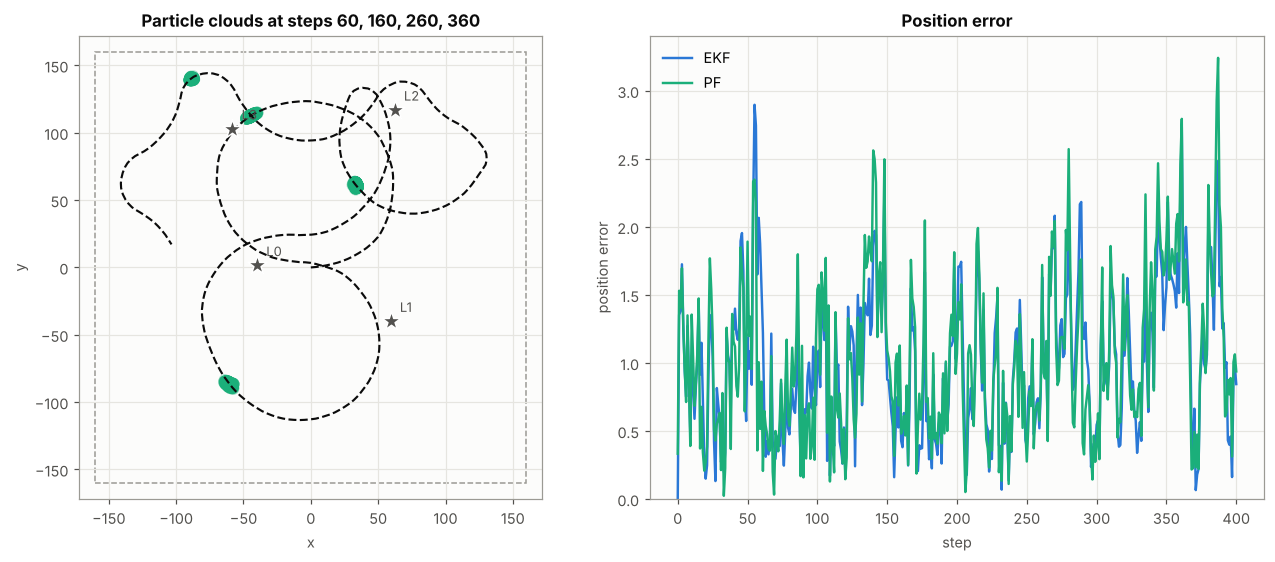

EKF: RMSE 1.13,  0.09 ms/step
PF: RMSE 1.18,  0.71 ms/step


In [4]:
pf = ParticleFilter(world, 1000, init=(run.truth[0], P0), seed=0)
r_pf = run_filter(pf, run, keep_snapshots=True)
r_ekf = run_filter(EKF.from_world(world, run.truth[0], P0), run)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw=dict(width_ratios=[1, 1.15]))
viz.plot_world(a1, world)
viz.plot_path(a1, run.truth, "truth", label="true path")
for t in (60, 160, 260, 360):
    parts, wts = r_pf.snapshots[t]
    viz.plot_particles(a1, parts, wts)
a1.set_title("Particle clouds at steps 60, 160, 260, 360")
viz.plot_error_over_time(a2, [r_ekf, r_pf], run.truth)
a2.set_title("Position error")
plt.tight_layout(); plt.show()
for r in (r_ekf, r_pf):
    print(f"{r.name}: RMSE {position_rmse(r.means, run.truth, skip=10):.2f},  {1000 * r.seconds / run.n_steps:.2f} ms/step")

Same accuracy, about eight times the cost. When the belief really is close to a Gaussian, the
particle filter has nothing to add. Its strengths are elsewhere.

## 5. Global localisation: the mower could be anywhere

A Kalman filter must be given a starting guess. A particle filter can start from a
**uniform** belief over the whole lawn and all headings (`init="global"`).

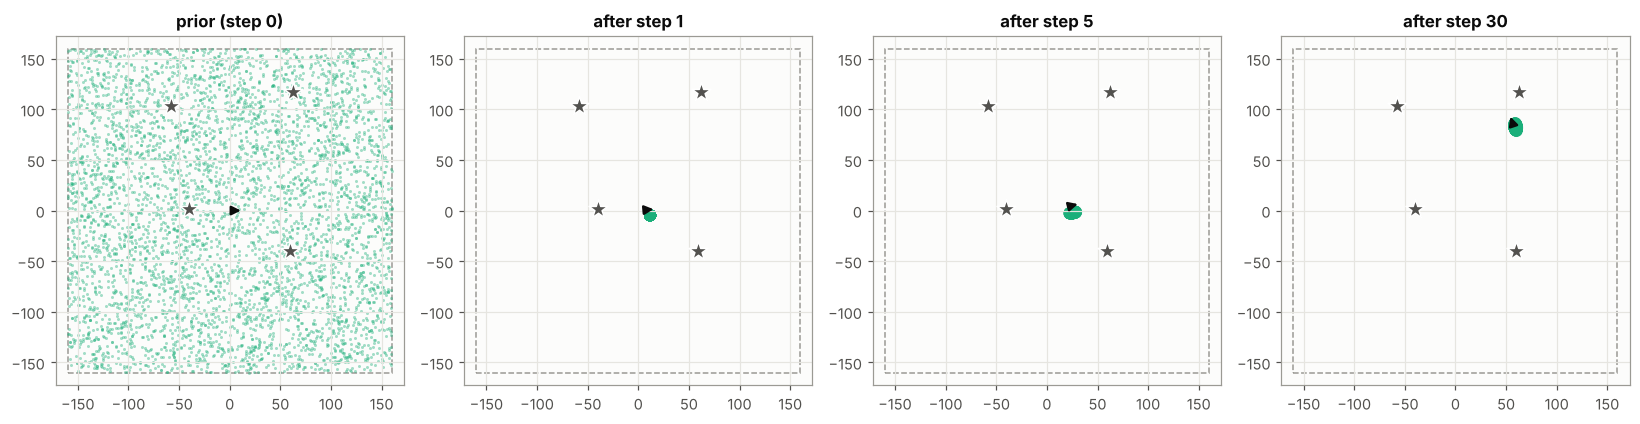

ESS after the first measurement: 1.0 out of 5000


In [5]:
pf = ParticleFilter(world, 5000, init="global", seed=0)
r_g = run_filter(pf, run, keep_snapshots=True)
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, t in zip(axes, (0, 1, 5, 30)):
    viz.plot_world(ax, world, label_landmarks=False)
    parts, wts = r_g.snapshots[t]
    viz.plot_particles(ax, parts, None if t == 0 else wts, alpha=0.4)
    viz.plot_pose(ax, run.truth[t], size=14)
    ax.set_title("prior (step 0)" if t == 0 else f"after step {t}")
    ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()
print(f"ESS after the first measurement: {pf.ess_history[0]:.1f} out of {pf.N}")

The first measurement is so informative (four ranges and four bearings) that, among 5000
uniformly scattered particles, essentially **one** is compatible with it: ESS $\approx 1$.
After resampling, all 5000 particles are copies of that one, which is a few units from the
truth. The motion noise then spreads them out again and the cloud slides onto the mower.

This is **sample impoverishment**. The posterior is much narrower than the spacing between
the initial particles. How quickly the filter recovers depends on $N$:

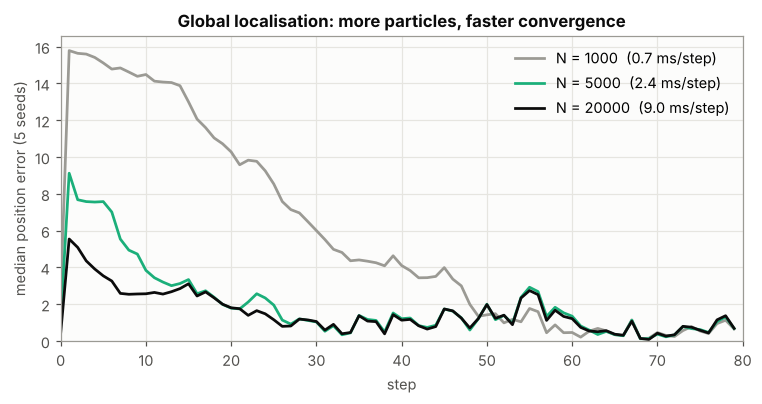

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
cols = {1000: viz.MUTED, 5000: viz.COLORS["PF"], 20000: viz.INK}
for N in (1000, 5000, 20000):
    errs, secs = [], []
    for s in range(5):
        rr = run_filter(ParticleFilter(world, N, init="global", seed=s), run)
        errs.append(position_error(rr.means, run.truth)); secs.append(rr.seconds)
    med = np.median(errs, 0)
    ax.plot(med[:80], color=cols[N], lw=1.8, label=f"N = {N}  ({1000 * np.mean(secs) / run.n_steps:.1f} ms/step)")
ax.legend()
ax.set_xlim(0, 80); ax.set_ylim(bottom=0); ax.set_xlabel("step"); ax.set_ylabel("median position error (5 seeds)")
ax.set_title("Global localisation: more particles, faster convergence")
plt.show()

Remedies besides more particles: **roughening** (jitter added after resampling,
`roughening=...`), a temporarily **tempered** likelihood ($p(z\mid x)^\beta$ with $\beta<1$) for
the first updates, or **sensor resetting** (drawing some particles directly from the
measurement). The cost is linear in $N$, and $N$ must grow quickly with the state dimension.
That is the particle filter's weakness.

## 6. When the mower does not know which landmark it sees

Suppose the sensor reports $(r, \phi)$ but not the landmark's identity. Then the likelihood of one measurement is a mixture over the
$M$ landmarks it could have come from:
$$
p(z \mid x) = \frac1M \sum_{j=1}^{M} \mathcal N\big(z;\, h_j(x),\, R\big)
$$
(`association="unknown"`). Attributing each measurement to the nearest landmark instead
amounts to replacing the sum by its largest term.

A particle filter handles this without fuss. To see the belief become genuinely
multimodal, put the four landmarks on a **square**. The lawn is then symmetric under
rotations by 90°, so four poses explain the measurements equally well, forever. (The noise is
raised here so that 20 000 particles resolve all four modes from a uniform start.)

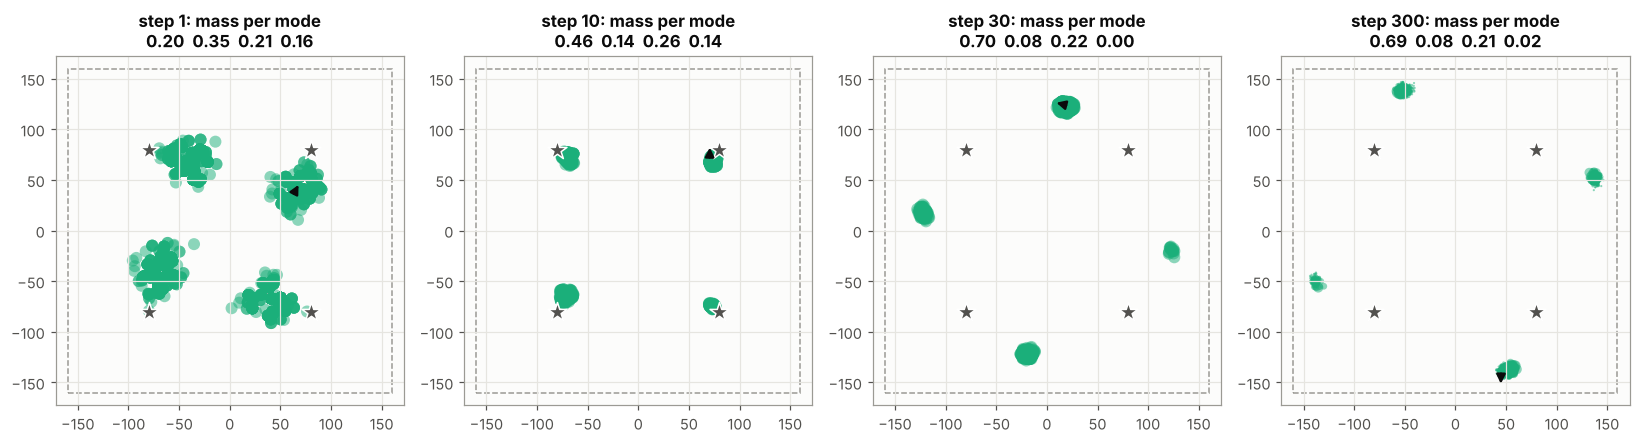

In [7]:
square = np.array([[-80, -80], [80, -80], [80, 80], [-80, 80]], float)
wsq = World(square, sigma_range=15.0, sigma_bearing=0.25)
rsq = simulate(wsq, n_steps=300, seed=1, x0=(60.0, 30.0, 1.0))
pf = ParticleFilter(wsq, 20000, init="global", association="unknown", seed=1)
r_sq = run_filter(pf, rsq, keep_snapshots=True)

def mode_masses(parts, wts, truth_xy):
    out = []
    for k in range(4):
        c, s = np.cos(k * np.pi / 2), np.sin(k * np.pi / 2)
        q = np.array([[c, -s], [s, c]]) @ truth_xy
        out.append(wts[np.hypot(*(parts[:, :2] - q).T) < 25].sum())
    return np.array(out)

fig, axes = plt.subplots(1, 4, figsize=(15, 4.1))
for ax, t in zip(axes, (1, 10, 30, 300)):
    viz.plot_world(ax, wsq, label_landmarks=False)
    parts, wts = r_sq.snapshots[t]
    viz.plot_particles(ax, parts, wts, alpha=0.5)
    viz.plot_pose(ax, rsq.truth[t], size=16)
    mm = mode_masses(parts, wts, rsq.truth[t, :2])
    ax.set_title(f"step {t}: mass per mode\n" + "  ".join(f"{m:.2f}" for m in mm))
    ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

* At first the cloud splits into **four** clusters, one per rotation of the true pose (the
  arrow). This is the correct posterior, and no Gaussian can represent it.
* By symmetry each mode should keep a mass of exactly $1/4$ forever. It does not. Resampling
  is random, so the masses perform a random walk, the "genetic drift" of the particle
  population. By step 30 one mode holds 70% of the mass and another 0.5% (fewer than 100 of
  the 20 000 particles). A mode that loses its last particle can never come back, and the
  filter then claims a certainty that the data do not support. This is the particle filter's
  version of over-confidence.
* The point estimate (the weighted mean) is meaningless here: it lies near the centre of the
  lawn, where the mower is not. Report the modes instead.

With fewer particles the modes die much sooner. Number of modes still holding particles:

In [8]:
for N in (2000, 5000):
    for seed in range(3):
        rr = run_filter(ParticleFilter(wsq, N, init="global", association="unknown", seed=seed), rsq, keep_snapshots=True)
        alive = []
        for t in (1, 10, 30, 300):
            parts, _ = rr.snapshots[t]
            counts = []
            for k in range(4):
                c, s_ = np.cos(k * np.pi / 2), np.sin(k * np.pi / 2)
                q = np.array([[c, -s_], [s_, c]]) @ rsq.truth[t, :2]
                counts.append(np.sum(np.hypot(*(parts[:, :2] - q).T) < 30))
            alive.append(int(np.sum(np.array(counts) > 0)))
        print(f"N = {N:5d}, seed {seed}: modes alive at steps 1, 10, 30, 300 = {alive}")

N =  2000, seed 0: modes alive at steps 1, 10, 30, 300 = [4, 2, 1, 1]


N =  2000, seed 1: modes alive at steps 1, 10, 30, 300 = [4, 2, 1, 1]


N =  2000, seed 2: modes alive at steps 1, 10, 30, 300 = [4, 4, 1, 1]


N =  5000, seed 0: modes alive at steps 1, 10, 30, 300 = [4, 3, 2, 2]


N =  5000, seed 1: modes alive at steps 1, 10, 30, 300 = [4, 3, 1, 1]


N =  5000, seed 2: modes alive at steps 1, 10, 30, 300 = [4, 3, 2, 1]


## 7. The kidnapped mower

**"Kidnapped"** is the standard name in robotics (the *kidnapped robot problem*) for a robot
that is picked up and moved somewhere else without being told. For our mower: someone lifts
it and puts it down on another part of the lawn.

Here, at step 200 the true pose jumps to $(100, -100)$, facing west. The filter keeps
receiving ordinary commands and measurements, and nothing tells it that the mower has moved.
This is harder than global localisation (section 5). There the filter *knows* that it does
not know where the mower is. Here it is **confidently wrong**: it must first discover that its
belief is wrong before it can find the mower again. A converged particle filter has no
particles near the new pose, so it can only crawl there through the motion noise, if at all.

**Augmented MCL** (Thrun, Burgard & Fox, *Probabilistic Robotics*, §8.3.5) monitors the
average measurement likelihood with a slow and a fast exponential average,
$w_{\text{slow}}$ and $w_{\text{fast}}$. When the fast one drops below the slow one, the
measurements have suddenly become hard to explain. The filter then replaces a fraction
$\max(0, 1 - w_{\text{fast}}/w_{\text{slow}})$ of the particles by uniformly random ones
(`recovery=(alpha_slow, alpha_fast)`).

Eight kidnappings, unknown data association, 3000 particles:

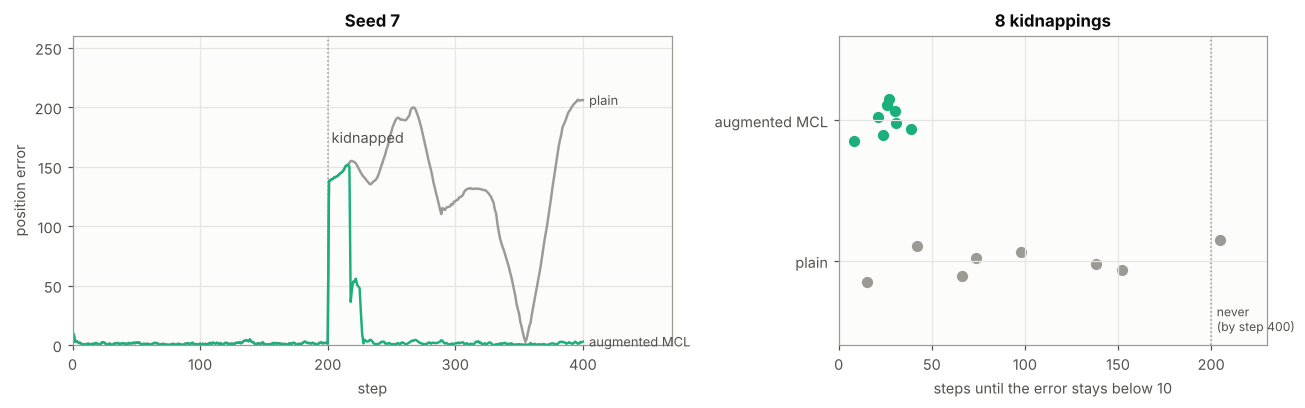

plain          steps to recover: [15, 66, 152, 138, 74, 98, 42, None]
augmented MCL  steps to recover: [8, 24, 39, 31, 21, 30, 26, 27]


In [9]:
rec_times = {"plain": [], "augmented MCL": []}
examples = {}
for s in range(8):
    rk = simulate(world, n_steps=400, seed=s, kidnap=(200, (100.0, -100.0, np.pi)))
    for label, rec in [("plain", None), ("augmented MCL", (0.001, 0.1))]:
        rr = run_filter(ParticleFilter(world, 3000, init="global", association="unknown",
                                       roughening=0.5, recovery=rec, seed=s), rk)
        pe = position_error(rr.means, rk.truth)
        bad = np.flatnonzero(pe[201:] >= 10)  # recovered = error below 10 from then on
        k = 0 if len(bad) == 0 else bad[-1] + 1
        rec_times[label].append(k + 1 if k < len(pe) - 201 else np.nan)
        if s == 7:
            examples[label] = pe

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.4, 1]))
a1.axvline(200, color=viz.MUTED, lw=1, ls=":")
a1.annotate("kidnapped", (203, 170), color=viz.INK_2)
a1.plot(examples["plain"], color=viz.MUTED, lw=1.6)
a1.plot(examples["augmented MCL"], color=viz.COLORS["PF"], lw=1.6)
a1.set_ylim(0, 260); a1.set_xlim(0, 470)
viz.label_line_end(a1, examples["plain"], "plain")
viz.label_line_end(a1, examples["augmented MCL"], "augmented MCL")
a1.set_xlabel("step"); a1.set_ylabel("position error"); a1.set_title("Seed 7")
for k, (label, ts) in enumerate(rec_times.items()):
    ts = np.array(ts, float)
    c = viz.MUTED if label == "plain" else viz.COLORS["PF"]
    a2.scatter(np.where(np.isnan(ts), 205, ts), np.full(len(ts), k) + np.linspace(-0.15, 0.15, len(ts)), s=40, color=c)
a2.set_yticks([0, 1], list(rec_times)); a2.set_ylim(-0.6, 1.6)
a2.axvline(200, color=viz.MUTED, lw=1, ls=":"); a2.annotate("never\n(by step 400)", (203, -0.5), color=viz.INK_2, fontsize=8)
a2.set_xlim(0, 230); a2.set_xlabel("steps until the error stays below 10"); a2.set_title("8 kidnappings")
plt.tight_layout(); plt.show()
for label, ts in rec_times.items():
    print(f"{label:14s} steps to recover: {[None if np.isnan(t) else int(t) for t in ts]}")

Without injection the filter usually finds its way back eventually, by luck and roughening,
but slowly, and it can lose the mower again (seed 7). With augmented MCL it recovers within a few dozen
steps every time. While tracking normally it injects only a handful of random particles,
which cost a little accuracy.

## 8. Summary

| | Kalman family | particle filter |
|---|---|---|
| belief | one Gaussian | any shape |
| models | linearised (EKF) or sigma points (UKF) | used as they are |
| unknown start | needs a guess | uniform prior works (with enough particles) |
| data association | must be decided before the update | can be marginalised |
| cost | $O(n^3)$, tiny | $O(N)$ model evaluations, $N$ grows fast with dimension |
| failure mode | over-confidence, divergence | impoverishment, lost modes |

The last notebook puts all filters side by side on the same scenarios.